# Explore the Data

### Imports

In [1]:
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

### Get the train set to explore

In [ ]:
data = pd.read_parquet('train_set.parquet')

### Looking into each feature and its attributes.

| Name | Type | % Missing | Noisiness & Noise Type | Usefulness for Task | Type of Distribution |
| :--- | :--- | :--- | :--- | :--- | :--- |
| `year` | Structured Numerical (Bounded: 1947–2025) | 0.00% | Deterministic (no noise) | Low to Moderate (captures long-term climate drift / warming trends) | Uniform (sequential annual index) |
| `phil_pred` | Categorical (Binary) | 0.00% | High noise (stochastic prediction & subjective human interpretation) | Low to Moderate (baseline heuristic; groundhog accuracy ~39%) | Binary / Bernoulli |
| `farm_avg_temp_mean_feb` | Bounded Numerical (°F) | 0.00% | Low to Moderate (stochastic daily weather fluctuations, station rounding) | High (direct thermal indicator of late-winter local warming) | Gaussian / Normal (skew = 0.02) |
| `farm_avg_temp_mean_jan` | Bounded Numerical (°F) | 1.75% | Low to Moderate (stochastic daily weather fluctuations, missing data) | Moderate (early winter thermal baseline) | Gaussian / Normal (skew = 0.08) |
| `farm_min_temp_min_feb` | Bounded Numerical (°F) | 0.00% | Moderate (arctic snap outliers, sensor noise) | Moderate (extreme cold freezes ground and delays thaw) | Gaussian / Near-Normal (skew = 0.01) |
| `farm_min_temp_min_jan` | Bounded Numerical (°F) | 1.75% | Moderate (arctic snap outliers, missing values) | Low to Moderate (Jan freeze snaps have limited impact on late March) | Gaussian / Near-Normal (skew = -0.03) |
| `farm_max_temp_max_feb` | Bounded Numerical (°F) | 0.00% | Moderate (warm spell outliers, sensor noise) | High (unseasonable warm spikes spur early snowmelt) | Slightly Left-Skewed (skew = -0.51) |
| `farm_max_temp_max_jan` | Bounded Numerical (°F) | 1.75% | Moderate (warm spell outliers, missing values) | Low (mid-winter warm spikes rarely trigger early spring) | Gaussian / Normal (skew = 0.10) |
| `farm_precip_sum_feb` | Bounded Numerical (≥ 0 inches) | 0.00% | Moderate (stochastic precipitation events, gauge rounding) | Moderate (late-winter moisture impacts soil temperature retention) | Right-Skewed / Log-Normal (skew = 1.19) |
| `farm_precip_sum_jan` | Bounded Numerical (≥ 0 inches) | 0.00% | Moderate (stochastic precipitation events, gauge rounding) | Moderate (signals early winter storm intensity) | Right-Skewed (skew = 0.77) |
| `farm_snowfall_sum_feb` | Bounded Numerical (≥ 0 inches) | 0.00% | High (blizzard outliers, measurement variability) | High (negative correlation with early spring; snow reflects radiation) | Heavily Right-Skewed (skew = 1.40) |
| `farm_snowfall_sum_jan` | Bounded Numerical (≥ 0 inches) | 0.00% | High (blizzard outliers, measurement variability) | Low (early snowpack often melts during mid-winter thaws) | Heavily Right-Skewed (skew = 1.83) |
| `farm_snowdepth_mean_feb` | Bounded Numerical (≥ 0 inches) | 0.00% | Moderate to High (local drift noise, physical measurement rounding) | High (persistent late snow insulates ground and delays spring) | Heavily Right-Skewed / Zero-Inflated (skew = 2.24) |
| `farm_snowdepth_mean_jan` | Bounded Numerical (≥ 0 inches) | 0.00% | Moderate to High (local drift noise, physical measurement rounding) | Low (January snowpack resets after mid-winter melts) | Heavily Right-Skewed / Zero-Inflated (skew = 2.70) |
| `farm_freezing_days_feb` | Bounded Discrete Integer [0, 29] | 0.00% | Low (threshold discretization noise near 32°F) | Low to Moderate (ceiling effect: almost every Feb has high freezing days) | Left-Skewed / Bounded High (skew = -3.60) |
| `farm_freezing_days_jan` | Bounded Discrete Integer [0, 31] | 0.00% | Low (threshold discretization noise near 32°F) | Moderate (measures general winter severity) | Left-Skewed / Bounded High (skew = -3.34) |
| `farm_snow_cover_days_feb` | Bounded Discrete Integer [0, 29] | 0.00% | Low to Moderate (discretization noise, patchy snow drift noise) | High (direct count of high-albedo days suppressing surface heating) | Bounded / Near-Symmetric (skew = 0.30) |
| `farm_snow_cover_days_jan` | Bounded Discrete Integer [0, 31] | 0.00% | Low to Moderate (discretization noise, patchy snow drift noise) | Low (Jan snow cover duration shows minimal correlation) | Broadly Bounded / Uniform-like (skew = -0.01) |
| `soil_temp_mean_feb` | Bounded Numerical (°C) | 0.00% | Low (probe calibration noise, depth thermal variance) | Moderate (direct measure of root-zone thermal conditions) | Gaussian / Slightly Right-Skewed (skew = 0.49) |
| `soil_temp_mean_jan` | Bounded Numerical (°C) | 0.00% | Low (probe calibration noise, depth thermal variance) | Moderate (inversely tracks deep frost penetration) | Gaussian / Near-Normal (skew = 0.22) |
| `soil_temp_min_feb` | Bounded Numerical (°C) | 0.00% | Moderate (localized cold frost spike noise) | Low to Moderate (measures sub-surface extreme freeze) | Moderately Left-Skewed (skew = -0.75) |
| `soil_temp_min_jan` | Bounded Numerical (°C) | 0.00% | Moderate (localized cold frost spike noise) | Moderate (negative correlation with early spring outcome) | Slightly Left-Skewed (skew = -0.50) |
| `soil_temp_max_feb` | Bounded Numerical (°C) | 0.00% | Moderate (solar radiation surface heating noise) | Moderate (signals topsoil warming events) | Gaussian / Right-Skewed (skew = 0.45) |
| `soil_temp_max_jan` | Bounded Numerical (°C) | 0.00% | Moderate (solar radiation surface heating noise) | Low (negligible predictive correlation) | Gaussian / Near-Normal (skew = 0.13) |
| `soil_moisture_mean_feb` | Bounded Numerical [0.0, 1.0] | 0.00% | Low (sensor electronic drift, compaction variability) | High (saturated soil slows thermal response due to high heat capacity) | Gaussian / Slightly Left-Skewed (skew = -0.29) |
| `soil_moisture_mean_jan` | Bounded Numerical [0.0, 1.0] | 0.00% | Low (sensor electronic drift, compaction variability) | Moderate (signals late winter water retention) | Gaussian / Slightly Left-Skewed (skew = -0.30) |
| `soil_thawed_days_feb` | Bounded Discrete Integer [0, 29] | 0.00% | Low (discretization noise around 0°C threshold) | Moderate (tally of active soil biological/thermal activity days) | Discrete Bounded / Right-Skewed (skew = 0.39) |
| `soil_thawed_days_jan` | Bounded Discrete Integer [0, 31] | 0.00% | Low (discretization noise around 0°C threshold) | Moderate (inversely related to winter frost persistence) | Discrete Bounded / Right-Skewed (skew = 0.32) |
| `om_temp_mean_feb` | Bounded Numerical (°C) | 0.00% | Low (reanalysis grid model smoothing noise) | High (regional synoptic thermal baseline, positive correlation) | Slightly Left-Skewed / Gaussian (skew = -0.41) |
| `om_temp_mean_jan` | Bounded Numerical (°C) | 0.00% | Low (reanalysis grid model smoothing noise) | Low (January regional mean temp shows negligible direct impact) | Gaussian / Near-Normal (skew = 0.16) |
| `om_temp_min_feb` | Bounded Numerical (°C) | 0.00% | Low to Moderate (grid model extreme estimation noise) | Moderate (regional cold minimums) | Gaussian / Symmetric (skew = 0.07) |
| `om_temp_min_jan` | Bounded Numerical (°C) | 0.00% | Low to Moderate (grid model extreme estimation noise) | Low (regional Jan minimums show minimal impact) | Gaussian / Symmetric (skew = 0.11) |
| `om_temp_max_feb` | Bounded Numerical (°C) | 0.00% | Low to Moderate (grid model surface radiation noise) | High (regional warm daytime peaks signal synoptic spring warm-up) | Slightly Left-Skewed (skew = -0.30) |
| `om_temp_max_jan` | Bounded Numerical (°C) | 0.00% | Low to Moderate (grid model surface radiation noise) | Low (Jan regional maximums show near-zero correlation) | Gaussian / Near-Normal (skew = -0.18) |
| `om_precip_sum_feb` | Bounded Numerical (≥ 0 mm) | 0.00% | Low to Moderate (grid cell spatial interpolation noise) | Moderate (regional moisture accumulation) | Right-Skewed (skew = 0.82) |
| `om_precip_sum_jan` | Bounded Numerical (≥ 0 mm) | 0.00% | Low to Moderate (grid cell spatial interpolation noise) | Moderate (signals general winter storm activity) | Right-Skewed (skew = 0.96) |
| `om_snowfall_sum_feb` | Bounded Numerical (≥ 0 cm) | 0.00% | Moderate (snow-equivalent conversion model noise) | High (strong inverse correlation with early spring outcome) | Heavily Right-Skewed (skew = 1.32) |
| `om_snowfall_sum_jan` | Bounded Numerical (≥ 0 cm) | 0.00% | Moderate (snow-equivalent conversion model noise) | Moderate (regional January snow accumulation) | Heavily Right-Skewed (skew = 1.48) |
| `om_sunshine_hours_sum_feb` | Bounded Numerical (≥ 0 hours) | 0.00% | Low (satellite solar radiation estimation noise) | Low to Moderate (accumulated late-winter solar radiation) | Gaussian / Slightly Left-Skewed (skew = -0.39) |
| `om_sunshine_hours_sum_jan` | Bounded Numerical (≥ 0 hours) | 0.00% | Low (satellite solar radiation estimation noise) | Moderate (inverse correlation with early spring) | Gaussian / Near-Normal (skew = -0.14) |
| `om_freezing_days_feb` | Bounded Discrete Integer [0, 29] | 0.00% | Low (grid cell spatial aggregation discretization noise) | Low (ceiling effect in winter climate) | Moderately Left-Skewed (skew = -0.74) |
| `om_freezing_days_jan` | Bounded Discrete Integer [0, 31] | 0.00% | Low (grid cell spatial aggregation discretization noise) | Low (ceiling effect in winter climate) | Heavily Left-Skewed (skew = -1.26) |
| `oni_prev_nov` | Bounded Numerical Index [-3.0, +3.0] | 7.02% | Low (smoothed 3-month ocean temperature anomaly noise) | Low to Moderate (teleconnection indicator for ENSO climate drivers) | Gaussian / Symmetric (skew = -0.04) |
| `oni_prev_dec` | Bounded Numerical Index [-3.0, +3.0] | 7.02% | Low (smoothed 3-month ocean temperature anomaly noise) | Low to Moderate (teleconnection indicator for ENSO climate drivers) | Gaussian / Symmetric (skew = -0.08) |
| `early_spring` | Categorical (Binary Target) | 0.00% | Low (ground truth verification label) | Target Variable | Binary / Bernoulli (~28% True) |

### Target Attribute:

Our target attribute is the `early_spring` feature. It is categorical and denoted by 0/1 or true/false to mark if it is or is not an early spring for the given year. Lets explore it!

/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_96829/2252627196.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


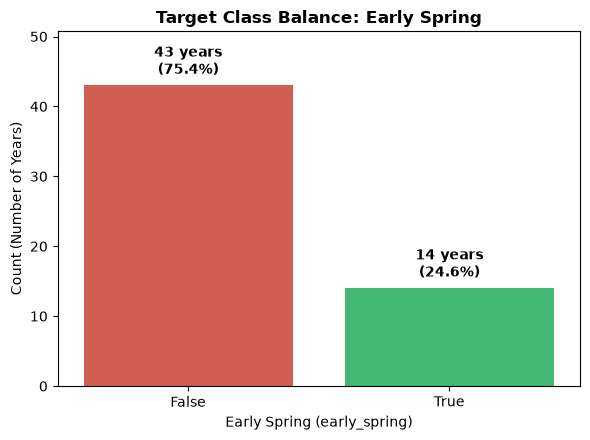

In [3]:
# Calculate counts and percentages
counts = data["early_spring"].value_counts()
pcts = data["early_spring"].value_counts(normalize=True) * 100

# Create bar plot
plt.figure(figsize=(6, 4.5))
ax = sns.barplot(
    x=counts.index.astype(str),
    y=counts.values,
    palette=["#e74c3c", "#2ecc71"],
)

# Chart styling
plt.title(
    "Target Class Balance: Early Spring", fontsize=12, fontweight="bold"
)
plt.xlabel("Early Spring (early_spring)", fontsize=10)
plt.ylabel("Count (Number of Years)", fontsize=10)
plt.ylim(0, max(counts.values) * 1.18)

# Add count and percentage labels above each bar
for i, (count, pct) in enumerate(zip(counts.values, pcts.values)):
  ax.text(
      i,
      count + 1,
      f"{count} years\n({pct:.1f}%)",
      ha="center",
      va="bottom",
      fontsize=10,
      fontweight="bold",
  )

plt.tight_layout()
plt.show()

There is a huge class imbalance with our target feature. only ~25% of the data is marked as early spring with the other 75% being a later or "on time" spring. This will need to be addressed later when we are training our models. I suspect if not handled, it will skew a lot of our predictions in favor of choosing false. Looking to the other variables we have collected, I think looking at soil temperature in association with the positive and negative early spring years will be beneficial

/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_96829/4196447358.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/mw/b7c8xl6s051dz_4qjhppf1l00000gn/T/ipykernel_96829/4196447358.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


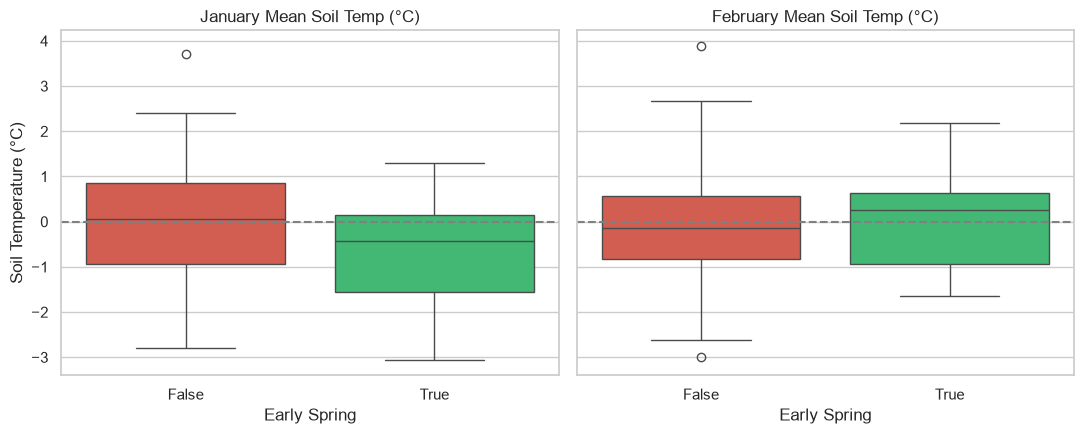

In [6]:
# Create two subplots that share the same Y-axis scale
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

# January
sns.boxplot(
    data=data,
    x="early_spring",
    y="soil_temp_mean_jan",
    ax=axes[0],
    palette=["#e74c3c", "#2ecc71"],
)
axes[0].set_title("January Mean Soil Temp (°C)")
axes[0].set_xlabel("Early Spring")
axes[0].set_ylabel("Soil Temperature (°C)")
axes[0].axhline(0, color="gray", linestyle="--")

# February
sns.boxplot(
    data=data,
    x="early_spring",
    y="soil_temp_mean_feb",
    ax=axes[1],
    palette=["#e74c3c", "#2ecc71"],
)
axes[1].set_title("February Mean Soil Temp (°C)")
axes[1].set_xlabel("Early Spring")
axes[1].axhline(0, color="gray", linestyle="--")

plt.tight_layout()
plt.show()

The difference in median soil temperature is quite high for both January and February. The difference in mean soil temperatures when going from January to February show high January median to lower February median for non early spring years and a low January median into higher February median for early spring years.

Looking at soil temperature, I have decided to divide them up by month by mean soil temp and if the mean temp resulted in an early spring or not. The first thing that sticks out to me is how lower January soil temperatures typically result in early spring. We can see that the early spring years go from a colder january to a warmer February. What is most interesting is how the median value for the subsequent february month for early spring years proceeds to get much warmer on average. Could the cold spikes in january show that the cold fronts experienced each year come sooner and would subsequently allow February months to be warmer? What is also interesting is that years that are not early spring show a much warmer January on average, whereas the February is around the same as the febraury months that result in an early spring year. My thought as to why this could be the case is possibly because the cold fronts come sooner in the winter and allow the lowest temperatures to hit January and taper off faster?

Also, this change in temperature from January to February makes me believe that a "temp delta" feature would be useful and insightful.